# DuckDB

In [19]:
import duckdb
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

path_parquet = 'Genius-song-lyrics-cleaned/data/*.parquet'

## Visão geral

In [20]:
# Columns
relation = duckdb.read_parquet(path_parquet)

print("## COLUMNS ##")
for i, column in enumerate(relation.columns, start=1):
    print(f"{i}. {column}")

## COLUMNS ##
1. title
2. tag
3. artist
4. year
5. views
6. features
7. lyrics
8. id
9. language_cld3
10. language_ft
11. language
12. lyrics_clean
13. char_len
14. word_len


In [21]:
# 20 first rows
query = f"""
    SELECT * FROM read_parquet('{path_parquet}') LIMIT 20;
"""

duckdb.sql(query).show()

┌────────────────────────────┬─────────┬───────────┬───────┬────────┬──────────────────────────────────────────────┬────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────

In [22]:
# Most relevant columns
query = f"""
    SELECT
        id,
        title,
        tag,
        artist,
        features,
        year,
        views,
        word_len,
        language_cld3,
        language_ft,
        language
    FROM read_parquet('{path_parquet}') LIMIT 20;
"""

duckdb.sql(query).show()

┌───────┬────────────────────────────┬─────────┬───────────┬──────────────────────────────────────────────┬───────┬────────┬──────────┬───────────────┬─────────────┬──────────┐
│  id   │           title            │   tag   │  artist   │                   features                   │ year  │ views  │ word_len │ language_cld3 │ language_ft │ language │
│ int64 │          varchar           │ varchar │  varchar  │                   varchar                    │ int64 │ int64  │  int64   │    varchar    │   varchar   │ varchar  │
├───────┼────────────────────────────┼─────────┼───────────┼──────────────────────────────────────────────┼───────┼────────┼──────────┼───────────────┼─────────────┼──────────┤
│     1 │ Killa Cam                  │ rap     │ Cam'ron   │ {"Cam\\'ron","Opera Steve"}                  │  2004 │ 173166 │      444 │ en            │ en          │ en       │
│     3 │ Can I Live                 │ rap     │ JAY-Z     │ {}                                           │  1996 │

## Unique values

In [23]:
# Count of unique values (distinct)
query = f"""
    SELECT
        approx_count_distinct(artist) AS distinct_artists,
        approx_count_distinct(tag) AS distinct_tags,
        approx_count_distinct(title) AS distinct_song_titles,
        approx_count_distinct(year) AS distinct_years
    FROM read_parquet('{path_parquet}')
    WHERE language='en';
"""

duckdb.sql(query).show()

┌──────────────────┬───────────────┬──────────────────────┬────────────────┐
│ distinct_artists │ distinct_tags │ distinct_song_titles │ distinct_years │
│      int64       │     int64     │        int64         │     int64      │
├──────────────────┼───────────────┼──────────────────────┼────────────────┤
│           372197 │             6 │              1893454 │            636 │
└──────────────────┴───────────────┴──────────────────────┴────────────────┘



In [24]:
# Average word count of songs
query = f"SELECT avg(word_len) FROM read_parquet('{path_parquet}');"

duckdb.sql(query).show()

┌────────────────────┐
│   avg(word_len)    │
│       double       │
├────────────────────┤
│ 234.28213254665758 │
└────────────────────┘



In [25]:
# Unique tags (genres)
query = f"""
    SELECT DISTINCT "tag" FROM read_parquet('{path_parquet}');
"""

duckdb.sql(query).show()

┌─────────┐
│   tag   │
│ varchar │
├─────────┤
│ pop     │
│ misc    │
│ rap     │
│ rock    │
│ rb      │
│ country │
└─────────┘



## Language

In [26]:
# Checking the language, language_ft (fasttext) and language_cld3 (google compact language detector v3) columns
query = f"""
    SELECT
        COUNT(*) FILTER (language IS DISTINCT FROM language_ft)
            AS lang_vs_lang_ft,

        COUNT(*) FILTER (language IS DISTINCT FROM language_ft)
            AS lang_vs_lang_cld3,

        COUNT(*) FILTER (language IS DISTINCT FROM language_ft)
            AS lang_ft_vs_lang_cld3

        FROM read_parquet('{path_parquet}')
        WHERE language='en';
"""

duckdb.sql(query).show()

┌─────────────────┬───────────────────┬──────────────────────┐
│ lang_vs_lang_ft │ lang_vs_lang_cld3 │ lang_ft_vs_lang_cld3 │
│      int64      │       int64       │        int64         │
├─────────────────┼───────────────────┼──────────────────────┤
│               0 │                 0 │                    0 │
└─────────────────┴───────────────────┴──────────────────────┘



## Artist

In [27]:
# General statistics about artist
query = f"""
    SELECT
        artist,
        COUNT(*) AS total_song_count
    FROM read_parquet('{path_parquet}')
    WHERE language='en'
    GROUP BY artist
    ORDER BY total_song_count DESC
    LIMIT 50;
"""

duckdb.sql(query).show(max_rows=50)

┌─────────────────────────────┬──────────────────┐
│           artist            │ total_song_count │
│           varchar           │      int64       │
├─────────────────────────────┼──────────────────┤
│ Genius English Translations │            13671 │
│ The Grateful Dead           │             2110 │
│ Emily Dickinson             │             1619 │
│ Abraham Lincoln             │             1492 │
│ Lil B                       │             1310 │
│ Frank Zappa                 │             1281 │
│ William Shakespeare         │             1258 │
│ Gucci Mane                  │             1245 │
│ Lil Wayne                   │             1213 │
│ KIDZ BOP Kids               │             1199 │
│ Guided by Voices            │             1188 │
│ Holy Bible (KJV)            │             1187 │
│ Tendon Levey                │             1183 │
│ Juice WRLD                  │             1170 │
│ Charles Dickens             │             1092 │
│ Frank Sinatra               │

In [28]:
# These are some artists that should be deleted
query = f"""
    SELECT
        COUNT(*),
        artist
    FROM read_parquet('{path_parquet}')
    WHERE
        language='en'
        AND artist ILIKE '%genius%'
        AND artist ILIKE '%translation%'
    GROUP BY artist
    ORDER BY artist ASC;
"""

duckdb.sql(query).show()

┌──────────────┬──────────────────────────────────┐
│ count_star() │              artist              │
│    int64     │             varchar              │
├──────────────┼──────────────────────────────────┤
│           34 │ Genius  (Chinese Translations)   │
│            4 │ Genius  (Japanese Translations)  │
│           12 │ Genius Arabic Translations ( )   │
│        13671 │ Genius English Translations      │
│            2 │ Genius Farsi Translations ( )    │
│            5 │ Genius Russian Translations ( )  │
│           36 │ Genius South Africa Translations │
│            4 │ Genius Swedish Translations      │
│           45 │ Genius Translations              │
└──────────────┴──────────────────────────────────┘



In [29]:
# Ordering artist by views ascending (least popular first)
# just to see if there are any other anomalies
# query = f"""
#     SELECT
#         artist,
#         views
#     FROM read_parquet('{path_parquet}')
#     WHERE language='en'
#     GROUP BY artist, views
#     ORDER BY views ASC;
# """

# duckdb.sql(query).show(max_rows=100)

In [30]:
# Checking cases with 'Lyrics' or 'Song' in artist name
query = f"""
    SELECT
        artist,
    FROM read_parquet('{path_parquet}')
    WHERE language='en'
    AND (artist ILIKE '%lyric%'
        OR artist ILIKE '%song%')
    GROUP BY artist
"""

duckdb.sql(query).show(max_rows=30)

┌──────────────────────────────────────────────────────┐
│                        artist                        │
│                       varchar                        │
├──────────────────────────────────────────────────────┤
│ Chris The Lyricist                                   │
│ Talk to Me Lyrics - Nick Brewer                      │
│ Kno the Meaning Lyrics - Future                      │
│ The 100 songs allstars                               │
│ Bruh... Lyrics - Lil Dicky                           │
│ Intro (Compton) Lyrics - Dr. Dre                     │
│ Darkside/Gone Lyrics - Dr. Dre                       │
│ R.I.P. 2 My Youth Lyrics - The Neighbourhood         │
│ Roll Up Lyrics - EMTee                               │
│ Children Lyrics - Justin Bieber                      │
│ Be the One Lyrics - Dua Lipa                         │
│ Jessi (), Microdot, Dumbfoundead, Lyricks            │
│ Kaspa De Lyrical                                     │
│ Lyrical Artist               

## NULL cases

In [31]:
# Checking NULL cases
query = f"""
    SELECT
        COUNT(*) FILTER (WHERE id IS NULL)              AS null_ids,
        COUNT(*) FILTER (WHERE title IS NULL)           AS null_titles,
        COUNT(*) FILTER (WHERE tag IS NULL)             AS null_tag,
        COUNT(*) FILTER (WHERE artist IS NULL)          AS null_artists,
        COUNT(*) FILTER (WHERE year IS NULL)            AS null_year,
        COUNT(*) FILTER (WHERE views IS NULL)           AS null_views,
        COUNT(*) FILTER (WHERE features IS NULL)        AS null_features,
        COUNT(*) FILTER (WHERE lyrics IS NULL)          AS null_lyrics,
        COUNT(*) FILTER (WHERE language_cld3 IS NULL)   AS null_lang_cld3,
        COUNT(*) FILTER (WHERE language_ft IS NULL)     AS null_lang_ft,
        COUNT(*) FILTER (WHERE language IS NULL)        AS null_lang,
        COUNT(*) FILTER (WHERE lyrics_clean IS NULL)    AS null_lyrics_clean,
        COUNT(*) FILTER (WHERE char_len IS NULL)        AS null_char_len,
        COUNT(*) FILTER (WHERE word_len IS NULL)        AS null_word_len
    FROM read_parquet('{path_parquet}')
    WHERE language='en';
"""

duckdb.sql(query).show()

┌──────────┬─────────────┬──────────┬──────────────┬───────────┬────────────┬───────────────┬─────────────┬────────────────┬──────────────┬───────────┬───────────────────┬───────────────┬───────────────┐
│ null_ids │ null_titles │ null_tag │ null_artists │ null_year │ null_views │ null_features │ null_lyrics │ null_lang_cld3 │ null_lang_ft │ null_lang │ null_lyrics_clean │ null_char_len │ null_word_len │
│  int64   │    int64    │  int64   │    int64     │   int64   │   int64    │     int64     │    int64    │     int64      │    int64     │   int64   │       int64       │     int64     │     int64     │
├──────────┼─────────────┼──────────┼──────────────┼───────────┼────────────┼───────────────┼─────────────┼────────────────┼──────────────┼───────────┼───────────────────┼───────────────┼───────────────┤
│        0 │         127 │        0 │            0 │         0 │          0 │             0 │           0 │              0 │            0 │         0 │                 0 │             

In [32]:
# Taking a look at the lyrics of null titles
# query = f"""
#     SELECT
#         artist,
#         lyrics
#     FROM read_parquet('{path_parquet}')
#     WHERE language='en' AND title IS NULL;
# """

# df_null_titles = duckdb.sql(query).df()

# print(f"Total rows found: {len(df_null_titles)}\n")

# if not df_null_titles.empty:
#     for idx, row in df_null_titles.head(10).iterrows():
#         print(f"Song #{idx + 1} | Artist: {row['artist']}")
#         print("-" * 40)

#         # Split lyrics by newline and grab the first 5 lines
#         lyric_lines = str(row['lyrics']).split('\n')
#         five_lines_preview = "\n".join(lyric_lines[:5])

#         print(five_lines_preview)

#         # Add a trailing indicator if the lyrics continue
#         if len(lyric_lines) > 5:
#             print("...")
# else:
#     print("No rows with NULL titles found!")

In [33]:
# Songs that have NULL titles are mostly from unpopular artists,
# so it might be better to just get rid of them

query = f"""
    SELECT
        artist
    FROM read_parquet('{path_parquet}')
    WHERE
        language='en' AND
        title IS NULL
    ORDER BY views DESC;
"""

duckdb.sql(query).show()
# To view all found:
# duckdb.sql(query).show(max_rows=127)

┌──────────────────────┐
│        artist        │
│       varchar        │
├──────────────────────┤
│ Tally Hall           │
│ Trippie Redd         │
│ Touch Amor           │
│ Pinegrove            │
│ RATKING              │
│ Elevation Worship    │
│ OSHUN                │
│ yxngxr1              │
│ Afourteen            │
│ VELVETEARS           │
│     ·                │
│     ·                │
│     ·                │
│ Slim Gutz            │
│ X Anonymous          │
│ Elliot James Mulhern │
│ Lawfermz             │
│ Azia (NYC)           │
│ Cloudwatch           │
│ Mathilda             │
│ KittyWilson          │
│ StonedAKhana         │
│ Grafhic              │
└──────────────────────┘
  127 rows (20 shown) 



## Duplicates

In [34]:
# Total of EN songs vs total of unique EN songs
# query = f"""
#     SELECT
#         COUNT(*) AS total_song_titles,
#         approx_count_distinct(title) AS distinct_song_titles,
#         (total_song_titles - distinct_song_titles) AS 'duplicate_song_titles'
#     FROM read_parquet('{path_parquet}')
#     WHERE language='en';
# """

# duckdb.sql(query).show()

In [35]:
# CHECK: duplicate freq is showing 0.5, which doesn't make much sense
# Checking same song titles where lyrics are different
# (using lyrics_clean to account for minor differences in tags)
print("Checking duplicate songs where title and lyrics are the same:")
query_metrics = f"""
    WITH group_count AS (
        SELECT
            title,
            md5(lyrics_clean) AS lyrics_hash,
            COUNT(*) AS cases
        FROM read_parquet('{path_parquet}')
        WHERE language='en'
            AND lyrics_clean IS NOT NULL
        GROUP BY title, md5(lyrics_clean)
    )

    SELECT
        SUM(cases) AS total_rows,
        COUNT(*) AS unique_combinations,
        (ANY_VALUE(total_songs) - COUNT(*)) AS total_duplicate_rows,
        ROUND(((ANY_VALUE(total_songs) - COUNT(*)) / SUM(cases)) * 100, 2) AS duplicate_freq,
        SUM(CASE WHEN cases > 1 THEN 1 ELSE 0 END) AS total_duplicate_songs
    FROM group_count,
        (SELECT COUNT(*) AS total_songs 
        FROM read_parquet('{path_parquet}') 
        WHERE language = 'en');
"""

duckdb.sql(query_metrics).show()

# Showing the most common duplicates
query_sample = f"""
    SELECT 
        title, 
        COUNT(*) AS occurrence_count
    FROM read_parquet('{path_parquet}')
    WHERE language = 'en'
        AND lyrics_clean IS NOT NULL
    GROUP BY title, md5(lyrics_clean)
    HAVING occurrence_count > 1
    ORDER BY occurrence_count DESC
    LIMIT 15;
"""

duckdb.sql(query_sample).show()

# These are duplicates where their lyrics are the same, but have different artists covering them
print("""
Duplicate songs are all covers by different artists.
Checking cases where title, artist and lyrics are the same:
""")
query_sample = f"""
    SELECT 
        title,
        COUNT(*) AS occurrence_count
    FROM read_parquet('{path_parquet}')
    WHERE language = 'en'
        AND lyrics_clean IS NOT NULL
    GROUP BY title, artist, md5(lyrics_clean)
    HAVING occurrence_count > 1
    ORDER BY occurrence_count DESC
    LIMIT 15;
"""

duckdb.sql(query_sample).show()

Checking duplicate songs where title and lyrics are the same:
┌────────────┬─────────────────────┬──────────────────────┬────────────────┬───────────────────────┐
│ total_rows │ unique_combinations │ total_duplicate_rows │ duplicate_freq │ total_duplicate_songs │
│   int128   │        int64        │        int64         │     double     │        int128         │
├────────────┼─────────────────────┼──────────────────────┼────────────────┼───────────────────────┤
│    3374198 │             3357003 │                17195 │           0.51 │                 13265 │
└────────────┴─────────────────────┴──────────────────────┴────────────────┴───────────────────────┘

┌────────────────────────────────────────┬──────────────────┐
│                 title                  │ occurrence_count │
│                varchar                 │      int64       │
├────────────────────────────────────────┼──────────────────┤
│ White Christmas                        │               81 │
│ Gloomy Sunday      

## Instrumental songs

In [36]:
# Checking if there are any instrumental songs we could delete
query = f"""
    SELECT
        COUNT(*) AS instrumental_count,
        lyrics
    FROM read_parquet('{path_parquet}')
    WHERE language='en'
    AND (lyrics ILIKE '%instrumental%'
        OR lyrics ILIKE '%tba%'
        OR lyrics ILIKE '%no lyrics%')
    AND length(lyrics) < 50
    GROUP BY lyrics;
"""

duckdb.sql(query).show()

┌────────────────────┬─────────┐
│ instrumental_count │ lyrics  │
│       int64        │ varchar │
└────────────────────┴─────────┘
             0 rows           



## Extreme length outliers (corrupted text)

In [37]:
query = f"""
    SELECT
        MIN(length(lyrics_clean)) AS min_chars,
        MAX(length(lyrics_clean)) AS max_chars,
        AVG(length(lyrics_clean)) AS avg_chars
    FROM read_parquet('{path_parquet}')
    WHERE language='en';
"""

duckdb.sql(query).show()

┌───────────┬───────────┬────────────────────┐
│ min_chars │ max_chars │     avg_chars      │
│   int64   │   int64   │       double       │
├───────────┼───────────┼────────────────────┤
│         0 │     99262 │ 1251.0198903561677 │
└───────────┴───────────┴────────────────────┘



In [38]:
# Empty lyrics
query = f"""
    SELECT
        COUNT(*) AS empty_lyrics_count
    FROM read_parquet('{path_parquet}')
    WHERE language = 'en'
    AND char_len = 0
"""

duckdb.sql(query).show()

┌────────────────────┐
│ empty_lyrics_count │
│       int64        │
├────────────────────┤
│                117 │
└────────────────────┘



In [39]:
# Lyrics with less than 100 characters
query = f"""
    WITH group_count AS (
        SELECT
            COUNT(*)
        FROM read_parquet('{path_parquet}')
        WHERE language = 'en'
        AND char_len < 100
        GROUP BY md5(lyrics_clean)
    )

    SELECT COUNT(*) AS '< 100 chars' FROM group_count;
"""

duckdb.sql(query).show()

┌─────────────┐
│ < 100 chars │
│    int64    │
├─────────────┤
│        8632 │
└─────────────┘



In [40]:
# Checking other long lyrics anomalies (> 25000)
query = f"""
    WITH group_count AS (
        SELECT
            COUNT(*)
        FROM read_parquet('{path_parquet}')
        WHERE language = 'en'
        AND char_len > 25000
        GROUP BY lyrics_clean
    )
    
    SELECT COUNT(*) AS '> 25000 chars' FROM group_count;
"""

duckdb.sql(query).show(max_rows=40)

┌───────────────┐
│ > 25000 chars │
│     int64     │
├───────────────┤
│          7059 │
└───────────────┘



In [41]:
# The Supreme Court of the United States
query = f"""
    SELECT
        COUNT(*) AS supreme_court_cases
    FROM read_parquet('{path_parquet}')
    WHERE language = 'en'
    AND artist = 'The Supreme Court of the United States'
"""

duckdb.sql(query).show()

┌─────────────────────┐
│ supreme_court_cases │
│        int64        │
├─────────────────────┤
│                 205 │
└─────────────────────┘



### Quantiles

In [42]:
# Some quartiles in the general distribution of lyrics length
query = f"""
    SELECT
        MIN(char_len)                                   AS min_chars,
        CAST(approx_quantile(char_len, 0.001) AS INT)   AS percentile_0_001,
        CAST(approx_quantile(char_len, 0.01) AS INT)    AS percentile_0_01,
        CAST(approx_quantile(char_len, 0.05) AS INT)    AS percentile_0_05,
        CAST(approx_quantile(char_len, 0.1) AS INT)     AS percentile_0_1,
        CAST(approx_quantile(char_len, 0.5) AS INT)     AS median_50th,
        CAST(approx_quantile(char_len, 0.9) AS INT)     AS percentile_0_9,
        CAST(approx_quantile(char_len, 0.95) AS INT)    AS percentile_0_95,
        CAST(approx_quantile(char_len, 0.99) AS INT)    AS percentile_0_99,
        CAST(approx_quantile(char_len, 0.999) AS INT)   AS percentile_0_999,
        MAX(char_len)                                   AS max_chars
    FROM read_parquet('{path_parquet}')
    WHERE language = 'en'
    AND lyrics_clean IS NOT NULL;
"""

duckdb.sql(query).show()

┌───────────┬──────────────────┬─────────────────┬─────────────────┬────────────────┬─────────────┬────────────────┬─────────────────┬─────────────────┬──────────────────┬───────────┐
│ min_chars │ percentile_0_001 │ percentile_0_01 │ percentile_0_05 │ percentile_0_1 │ median_50th │ percentile_0_9 │ percentile_0_95 │ percentile_0_99 │ percentile_0_999 │ max_chars │
│   int64   │      int32       │      int32      │      int32      │     int32      │    int32    │     int32      │      int32      │      int32      │      int32       │   int64   │
├───────────┼──────────────────┼─────────────────┼─────────────────┼────────────────┼─────────────┼────────────────┼─────────────────┼─────────────────┼──────────────────┼───────────┤
│         0 │               68 │             146 │             292 │            391 │         844 │           2167 │            2749 │            6722 │            37762 │     99262 │
└───────────┴──────────────────┴─────────────────┴─────────────────┴────────────

In [43]:
# # Making a sample to label which are real songs in the .99 percentile
# # query = f"""
#     SELECT
#         artist,
#         title,
#         char_len,
#         SUBSTRING(lyrics_clean, 1, 100) AS lyrics_preview
#     FROM read_parquet('{path_parquet}')
#     WHERE language = 'en'
#         AND (char_len > 3000 AND char_len < 6731)
#     ORDER BY char_len DESC
#     LIMIT 100;
# """

# df_export = duckdb.sql(query).df()

# # Exporting it to manually classify which are real songs, which aren't
# df_export.to_excel("percentile_0_99.ods", index=False)

In [44]:
# df_import = pd.read_excel("percentile_0_99.ods", engine="odf")

# print(f"Real songs in sample with 100 lyrics from 6705 to 6730 chars:\n{df_import['real_music'].sum()}")

In [45]:
# How many songs there are with less than 6730 chars
query = f"""
    SELECT 
        COUNT(*) as '< 6731'
    FROM read_parquet('{path_parquet}')
    WHERE language = 'en'
    AND char_len > 100 AND char_len < 6730
"""

duckdb.sql(query).show()

┌─────────┐
│ < 6731  │
│  int64  │
├─────────┤
│ 3332441 │
└─────────┘



> A cutoff point between 100 and 6730 chars looks good

In [46]:
# Some other cases with translation in the artist name
query = f"""
    SELECT
        COUNT(*) AS count_translation,
        COALESCE(artist, '============ GRAND TOTAL ============') AS artist --getting the grand total
    FROM read_parquet('{path_parquet}')
    WHERE language = 'en'
    AND artist ILIKE '%translation%'
    AND NOT artist ILIKE '%genius%'
    GROUP BY ROLLUP (artist)
    ORDER BY count_translation DESC;
"""

duckdb.sql(query).show()

┌───────────────────┬─────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────┐
│ count_translation │                                                                                       artist                                                                                        │
│       int64       │                                                                                       varchar                                                                                       │
├───────────────────┼─────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────┤
│               115 │ ============ GRAND TOTAL ============                                                                                                                             

### Graph of distribution of lyric size

In [47]:
query = f"""
    WITH binning AS (
        SELECT
            CAST(char_len / 100 AS INT) * 100 AS char_bucket
        FROM read_parquet('{path_parquet}')
        WHERE language = 'en'
        AND char_len BETWEEN 100 AND 6730
    )

    SELECT
        char_bucket,
        COUNT(*) AS song_count
    FROM binning
    GROUP BY char_bucket
    ORDER BY char_bucket;
"""

df_distribution = duckdb.sql(query).df()
print(df_distribution)

    char_bucket  song_count
0           100       27111
1           200       83465
2           300      137209
3           400      215772
4           500      282492
..          ...         ...
62         6300         472
63         6400         442
64         6500         437
65         6600         393
66         6700         304

[67 rows x 2 columns]


Plot successfully saved as 'lyric_length_distribution.png'!


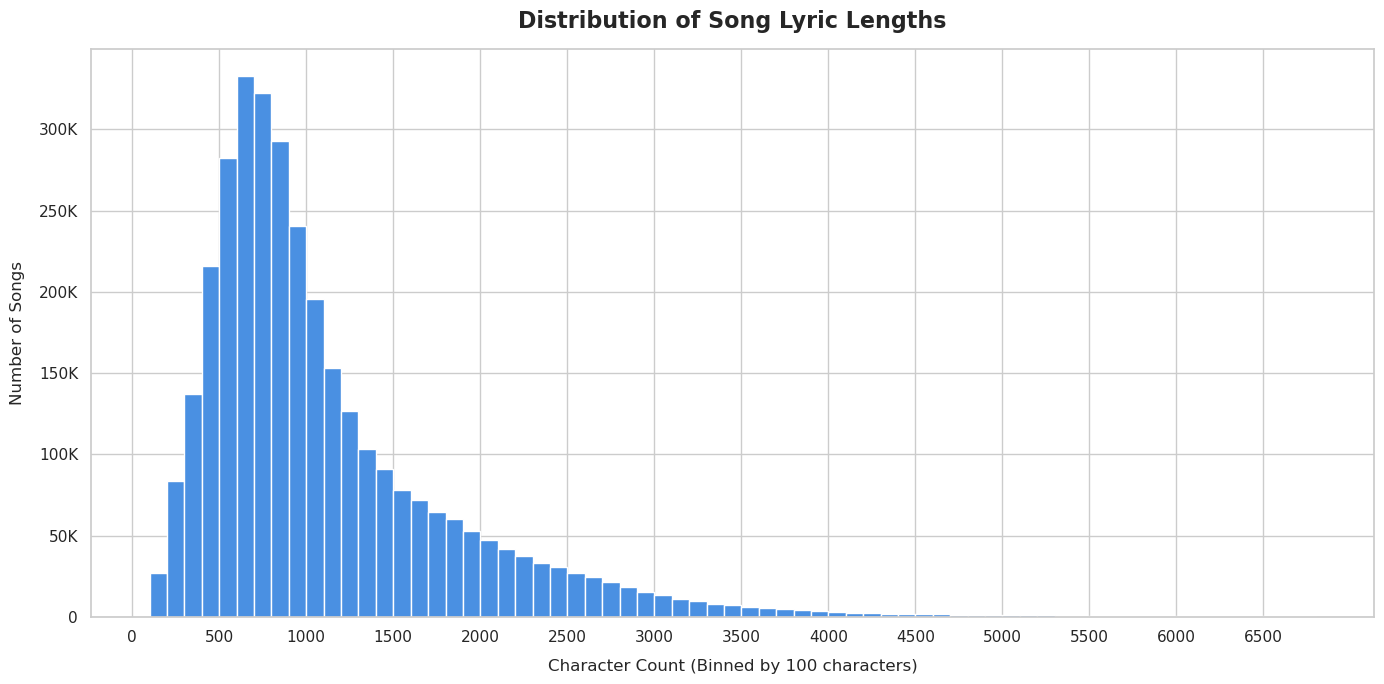

In [48]:
sns.set_theme(style="whitegrid")
plt.figure(figsize=(14, 7))

# We use Matplotlib's bar plot because our X-axis is numeric and continuous.
# Setting width=100 makes the bars touch each other, creating a true Histogram look.
plt.bar(
    df_distribution['char_bucket'], 
    df_distribution['song_count'], 
    width=100, 
    color='#4A90E2', 
    edgecolor='white',
    align='edge'
)

# Titles and Labels
plt.title("Distribution of Song Lyric Lengths", fontsize=16, pad=15, weight='bold')
plt.xlabel("Character Count (Binned by 100 characters)", fontsize=12, labelpad=10)
plt.ylabel("Number of Songs", fontsize=12, labelpad=10)

# Format X-axis to show ticks every 500 characters for readability
plt.xticks(range(0, 7000, 500))

# Format Y-axis to show 'K' (thousands) instead of long numbers like 150000
ax = plt.gca()
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, pos: f'{int(x/1000)}K' if x >= 1000 else int(x)))

plt.tight_layout()

# Save the plot
plt.savefig('lyric_length_distribution.png', dpi=300)
print("Plot successfully saved as 'lyric_length_distribution.png'!")

# Show the plot
plt.show()

### Graph of quantiles

In [49]:
query = f"""
    SELECT
        MIN(char_len)                                   AS min_chars,
        CAST(approx_quantile(char_len, 0.001) AS INT)   AS percentile_0_001,
        CAST(approx_quantile(char_len, 0.01) AS INT)    AS percentile_0_01,
        CAST(approx_quantile(char_len, 0.05) AS INT)    AS percentile_0_05,
        CAST(approx_quantile(char_len, 0.1) AS INT)     AS percentile_0_1,
        CAST(approx_quantile(char_len, 0.5) AS INT)     AS median_50th,
        CAST(approx_quantile(char_len, 0.9) AS INT)     AS percentile_0_9,
        CAST(approx_quantile(char_len, 0.95) AS INT)    AS percentile_0_95,
        CAST(approx_quantile(char_len, 0.99) AS INT)    AS percentile_0_99,
        CAST(approx_quantile(char_len, 0.999) AS INT)   AS percentile_0_999,
        MAX(char_len)                                   AS max_chars
    FROM read_parquet('{path_parquet}')
    WHERE language = 'en'
    AND lyrics_clean IS NOT NULL;
"""

df_quartile = duckdb.sql(query).df()

# Reshaping df (variable/value axes)
df_melted = df_quartile.melt(var_name='percentile', value_name='char_len')

print("Before:\n")
print(df_quartile)
print("\nAfter:\n")
print(df_melted)

Before:

   min_chars  percentile_0_001  percentile_0_01  percentile_0_05  \
0          0                67              146              292   

   percentile_0_1  median_50th  percentile_0_9  percentile_0_95  \
0             391          844            2166             2754   

   percentile_0_99  percentile_0_999  max_chars  
0             6622             39018      99262  

After:

          percentile  char_len
0          min_chars         0
1   percentile_0_001        67
2    percentile_0_01       146
3    percentile_0_05       292
4     percentile_0_1       391
5        median_50th       844
6     percentile_0_9      2166
7    percentile_0_95      2754
8    percentile_0_99      6622
9   percentile_0_999     39018
10         max_chars     99262


In [50]:
label_mapping = {
    'min_chars': 'Min (0%)',
    'percentile_0_001': '0.1%',
    'percentile_0_01': '1%',
    'percentile_0_05': '5%',
    'percentile_0_1': '10%',
    'median_50th': 'Median (50%)',
    'percentile_0_9': '90%',
    'percentile_0_95': '95%',
    'percentile_0_99': '99%',
    'percentile_0_999': '99.9%',
    'max_chars': 'Max (100%)'
}

df_melted['percentile_label'] = df_melted['percentile'].map(label_mapping)
print(df_melted)

          percentile  char_len percentile_label
0          min_chars         0         Min (0%)
1   percentile_0_001        67             0.1%
2    percentile_0_01       146               1%
3    percentile_0_05       292               5%
4     percentile_0_1       391              10%
5        median_50th       844     Median (50%)
6     percentile_0_9      2166              90%
7    percentile_0_95      2754              95%
8    percentile_0_99      6622              99%
9   percentile_0_999     39018            99.9%
10         max_chars     99262       Max (100%)


Plot successfully saved as 'lyric_length_percentiles.png'!


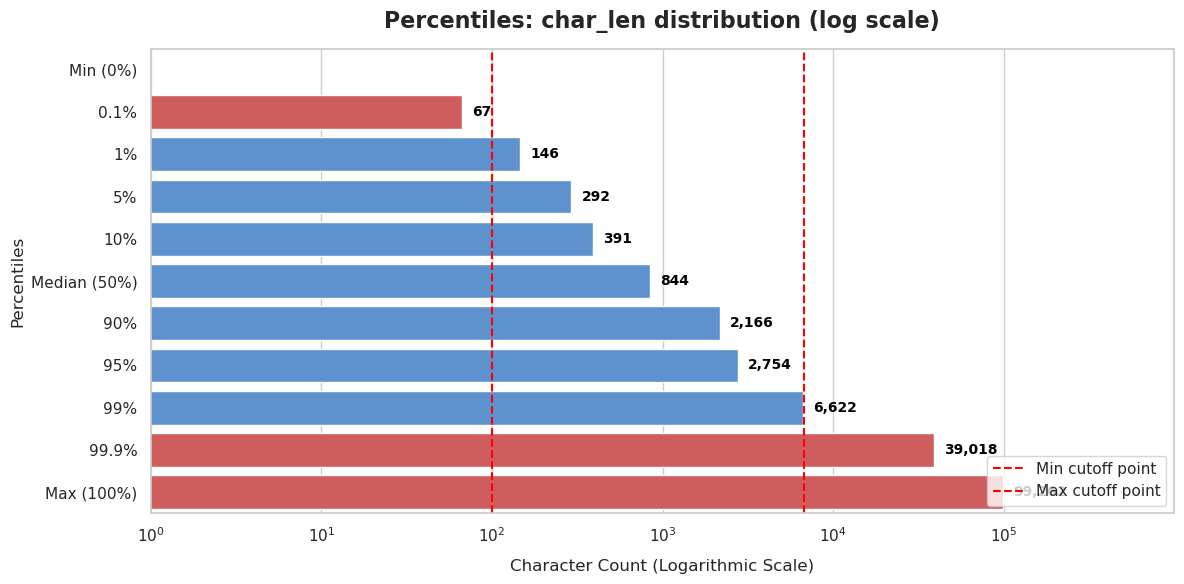

In [51]:
sns.set_theme(style="whitegrid")
plt.figure(figsize=(12, 6))

colors = ['#4A90E2' if val <= 6730 and val >=100 else '#E24A4A' for val in df_melted['char_len']]
ax = sns.barplot(
    x='char_len',
    y='percentile_label',
    data=df_melted,
    palette=colors,
    hue='percentile_label',
    legend=False
)

# We change x's scale to be logarithmic, so we can see both extremes properly
ax.set_xscale('log')

for i, p in enumerate(ax.patches):
    width = p.get_width()
    if width > 0:
        ax.text(
            width * 1.15, 
            p.get_y() + p.get_height() / 2, 
            f'{int(width):,}', 
            ha='left', 
            va='center', 
            fontsize=10, 
            color='black',
            weight='bold'
        )

plt.axvline(x=100, color='red', linestyle='--', linewidth=1.5, label='Min cutoff point')
plt.axvline(x=6730, color='red', linestyle='--', linewidth=1.5, label='Max cutoff point')

# Titles and Labels
plt.title("Percentiles: char_len distribution (log scale)", fontsize=16, pad=15, weight='bold')
plt.xlabel("Character Count (Logarithmic Scale)", fontsize=12, labelpad=10)
plt.ylabel("Percentiles", fontsize=12)
plt.xlim(1, df_melted['char_len'].max() * 10) # Pad limits so labels aren't cut off
plt.legend(loc='lower right')

plt.tight_layout()

# Save the plot
plt.savefig('lyric_length_percentiles.png', dpi=300)
print("Plot successfully saved as 'lyric_length_percentiles.png'!")

# Show the plot
plt.show()

### Maximum cutoff point

In [52]:
# Checking other maximum cutoff points
# Count of songs we would be left with
query = f"""
    SELECT
        COUNT(*) FILTER (WHERE char_len BETWEEN 100 AND 6730) AS count_6730, 
        COUNT(*) FILTER (WHERE char_len BETWEEN 100 AND 4000) AS count_4000,
        COUNT(*) FILTER (WHERE char_len BETWEEN 100 AND 4500) AS count_4500,
        COUNT(*) FILTER (WHERE char_len BETWEEN 100 AND 5000) AS count_5000
    FROM read_parquet('{path_parquet}')
    WHERE language = 'en';
"""

df_counts = duckdb.sql(query).df()

for col, row in df_counts.items():
    print(f"{col}: {df_counts[col][0]}")

count_6730 = df_counts['count_6730'][0]

dif_4000 = df_counts['count_6730'][0] - df_counts['count_4000'][0]
dif_4500 = df_counts['count_6730'][0] - df_counts['count_4500'][0]
dif_5000 = df_counts['count_6730'][0] - df_counts['count_5000'][0]

print(f"\nDifference between each band and 6730 (current hypothesis):\n")
print(f"From 4000 to 6730: {dif_4000} ({((dif_4000*100)/count_6730):.2f} %)")
print(f"From 4500 to 6730: {df_counts['count_6730'][0] - df_counts['count_4500'][0]} ({((dif_4500*100)/count_6730):.2f} %)")
print(f"From 5000 to 6730: {df_counts['count_6730'][0] - df_counts['count_5000'][0]} ({((dif_5000*100)/count_6730):.2f} %)")

count_6730: 3332903
count_4000: 3305032
count_4500: 3316271
count_5000: 3322576

Difference between each band and 6730 (current hypothesis):

From 4000 to 6730: 27871 (0.84 %)
From 4500 to 6730: 16632 (0.50 %)
From 5000 to 6730: 10327 (0.31 %)


In [53]:
# # Making some samples to label manually which ones are real songs
# # 4000
# query = f"""
#     SELECT
#         artist,
#         title,
#         char_len,
#         SUBSTRING(lyrics_clean, 1, 200) AS lyrics_preview
#     FROM read_parquet('{path_parquet}')
#     WHERE language = 'en'
#     AND char_len BETWEEN 100 AND 4000
#     ORDER BY char_len DESC
#     LIMIT 100;
# """

# # 4500
# df_export = duckdb.sql(query).df()
# df_export['real_song'] = 0 #making our label column (fill w/ 0)
# df_export.to_excel("sample_cutoff_4000.ods", index=False)

# query = f"""
#     SELECT
#         artist,
#         title,
#         char_len,
#         SUBSTRING(lyrics_clean, 1, 200) AS lyrics_preview
#     FROM read_parquet('{path_parquet}')
#     WHERE language = 'en'
#     AND char_len BETWEEN 100 AND 4500
#     ORDER BY char_len DESC
#     LIMIT 100;
# """

# df_export = duckdb.sql(query).df()
# df_export['real_song'] = 0 #making our label column (fill w/ 0)
# df_export.to_excel("sample_cutoff_4500.ods", index=False)

# # 5000
# query = f"""
#     SELECT
#         artist,
#         title,
#         char_len,
#         SUBSTRING(lyrics_clean, 1, 200) AS lyrics_preview
#     FROM read_parquet('{path_parquet}')
#     WHERE language = 'en'
#     AND char_len BETWEEN 100 AND 5000
#     ORDER BY char_len DESC
#     LIMIT 100;
# """

# df_export = duckdb.sql(query).df()
# df_export['real_song'] = 0 #making our label column (fill w/ 0)
# df_export.to_excel("sample_cutoff_5000.ods", index=False)

In [54]:
df_import = pd.read_excel("sample_cutoff_4000.ods", engine="odf")

print(f"Real songs in sample with 100 lyrics from 3997 to 4000 chars:\n{df_import['real_song'].sum()}")

Real songs in sample with 100 lyrics from 3997 to 4000 chars:
86


In [55]:
df_import = pd.read_excel("sample_cutoff_5000.ods", engine="odf")

print(f"Real songs in sample with 100 lyrics from 4989 to 5000 chars:\n{df_import['real_song'].sum()}")

Real songs in sample with 100 lyrics from 4989 to 5000 chars:
55


> keep using 6730 as the cutoff point (35 real songs in that sample)

In [56]:
# Cheking out an anomaly found in one of the samples (rapgenius.com)
query = f"""
    SELECT
        COUNT(*) AS rapgenius_count,
    FROM read_parquet('{path_parquet}')
    WHERE language = 'en'
    AND (lyrics_clean ILIKE '%rapgenius%' OR artist ILIKE '%rapgenius%' OR title ILIKE '%rapgenius%')
"""

duckdb.sql(query).show()

┌─────────────────┐
│ rapgenius_count │
│      int64      │
├─────────────────┤
│             285 │
└─────────────────┘



In [57]:
query = f"""
    SELECT
        title,
        artist,
        views
    FROM read_parquet('{path_parquet}')
    WHERE language = 'en'
    AND (lyrics_clean ILIKE '%rapgenius%' OR artist ILIKE '%rapgenius%' OR title ILIKE '%rapgenius%')
    ORDER BY views DESC;
"""

duckdb.sql(query).show()

┌────────────────────────────────────────────────────────────────────────────────┬──────────────────────────────────┬────────┐
│                                     title                                      │              artist              │ views  │
│                                    varchar                                     │             varchar              │ int64  │
├────────────────────────────────────────────────────────────────────────────────┼──────────────────────────────────┼────────┤
│ Rap Stats: Breaking Down The Words in Rap Lyrics Over Time                     │ SameOldShawn                     │ 100173 │
│ Eminem Dissed Me                                                               │ Anthony Fantano                  │  68102 │
│ Open Letter to Google About Rap Genius SEO                                     │ Genius Founders                  │  61727 │
│ Middle of the Cake                                                             │ Das Racist                  

## Views cutoff points

In [58]:
query = f"""
    SELECT
        COUNT(*)
    FROM read_parquet('{path_parquet}')
    WHERE language = 'en'
    AND views = 0;
"""

duckdb.sql(query).show()

┌──────────────┐
│ count_star() │
│    int64     │
├──────────────┤
│         4648 │
└──────────────┘



## Quantiles

In [59]:
# Quantiles
query = f"""
    SELECT
        MIN(views)                                   AS min_chars,
        CAST(approx_quantile(views, 0.001) AS INT)   AS percentile_0_001,
        CAST(approx_quantile(views, 0.01) AS INT)    AS percentile_0_01,
        CAST(approx_quantile(views, 0.05) AS INT)    AS percentile_0_05,
        CAST(approx_quantile(views, 0.1) AS INT)     AS percentile_0_1,
        CAST(approx_quantile(views, 0.5) AS INT)     AS median_50th,
        CAST(approx_quantile(views, 0.9) AS INT)     AS percentile_0_9,
        CAST(approx_quantile(views, 0.95) AS INT)    AS percentile_0_95,
        CAST(approx_quantile(views, 0.99) AS INT)    AS percentile_0_99,
        CAST(approx_quantile(views, 0.999) AS INT)   AS percentile_0_999,
        MAX(views)                                   AS max_chars
    FROM read_parquet('{path_parquet}')
    WHERE language = 'en'
    AND lyrics_clean IS NOT NULL;
"""

df_quartile = duckdb.sql(query).df()

df_melted = df_quartile.melt(var_name='percentile', value_name='views')

In [60]:
print(df_melted)

          percentile     views
0          min_chars         0
1   percentile_0_001         0
2    percentile_0_01         2
3    percentile_0_05         4
4     percentile_0_1         8
5        median_50th        90
6     percentile_0_9      2391
7    percentile_0_95      6824
8    percentile_0_99     53509
9   percentile_0_999    553869
10         max_chars  17575634


In [61]:
label_mapping = {
    'min_chars': 'Min (0%)',
    'percentile_0_001': '0.1%',
    'percentile_0_01': '1%',
    'percentile_0_05': '5%',
    'percentile_0_1': '10%',
    'median_50th': 'Median (50%)',
    'percentile_0_9': '90%',
    'percentile_0_95': '95%',
    'percentile_0_99': '99%',
    'percentile_0_999': '99.9%',
    'max_chars': 'Max (100%)'
}

df_melted['percentile_label'] = df_melted['percentile'].map(label_mapping)

In [62]:
print(df_melted)

          percentile     views percentile_label
0          min_chars         0         Min (0%)
1   percentile_0_001         0             0.1%
2    percentile_0_01         2               1%
3    percentile_0_05         4               5%
4     percentile_0_1         8              10%
5        median_50th        90     Median (50%)
6     percentile_0_9      2391              90%
7    percentile_0_95      6824              95%
8    percentile_0_99     53509              99%
9   percentile_0_999    553869            99.9%
10         max_chars  17575634       Max (100%)


Plot successfully saved as 'views_percentiles.png'!


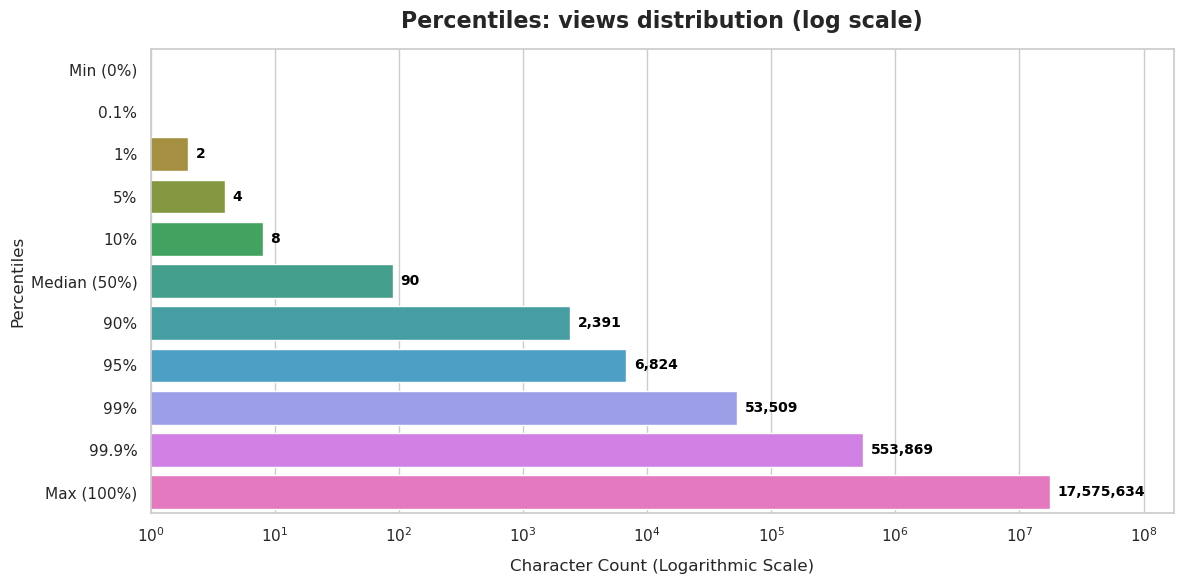

In [63]:
sns.set_theme(style="whitegrid")
plt.figure(figsize=(12, 6))

# colors = ['#4A90E2' if val <= 6730 and val >=100 else '#E24A4A' for val in df_melted['views']]
ax = sns.barplot(
    x='views',
    y='percentile_label',
    data=df_melted,
    # palette=colors,
    hue='percentile_label',
    legend=False
)

# We change x's scale to be logarithmic, so we can see both extremes properly
ax.set_xscale('log')

for i, p in enumerate(ax.patches):
    width = p.get_width()
    if width > 0:
        ax.text(
            width * 1.15, 
            p.get_y() + p.get_height() / 2, 
            f'{int(width):,}', 
            ha='left', 
            va='center', 
            fontsize=10, 
            color='black',
            weight='bold'
        )

# plt.axvline(x=100, color='red', linestyle='--', linewidth=1.5, label='Min cutoff point')
# plt.axvline(x=6730, color='red', linestyle='--', linewidth=1.5, label='Max cutoff point')

# Titles and Labels
plt.title("Percentiles: views distribution (log scale)", fontsize=16, pad=15, weight='bold')
plt.xlabel("Character Count (Logarithmic Scale)", fontsize=12, labelpad=10)
plt.ylabel("Percentiles", fontsize=12)
plt.xlim(1, df_melted['views'].max() * 10) # Pad limits so labels aren't cut off
# plt.legend(loc='lower right')

plt.tight_layout()

# Save the plot
plt.savefig('views_percentiles.png', dpi=300)
print("Plot successfully saved as 'views_percentiles.png'!")

# Show the plot
plt.show()

In [64]:
# Looking at songs around median
query = f"""
    SELECT
        artist,
        title,
        views,
        SUBSTRING(lyrics_clean, 1, 200) AS lyrics_preview
    FROM read_parquet('{path_parquet}')
    WHERE language = 'en'
        AND views BETWEEN 89 AND 91
    ORDER BY views DESC
    LIMIT 100;
"""

duckdb.sql(query).show(max_rows=100)

┌───────────────────────────────────────────┬───────────────────────────────────────────────────────────────────────────────┬───────┬──────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────┐
│                  artist                   │                                     title                                     │ views │                                                                                              lyrics_preview                                                                                              │
│                  varchar                  │                                    varchar                                    │ int64 │                                                                                                 varchar                                                                                         

# Data cleaning

In [65]:
# query = f"""
#     COPY (
#         SELECT *
#         FROM read_parquet('{path_parquet}')
#         WHERE language = 'en'
#             AND char_len BETWEEN 100 AND 6730
#             AND lyrics_clean IS NOT NULL
#             AND title IS NOT NULL
#             -- not having both genius AND translation in artist
#             AND NOT (artist ILIKE '%genius%'
#                 AND artist ILIKE '%translation%')
#             -- not having ONLY translation in artist
#             AND NOT artist ILIKE '%translation%'
#             AND NOT (lyrics_clean ILIKE '%rapgenius%'
#                 OR artist ILIKE '%rapgenius%'
#                 OR title ILIKE '%rapgenius%')
#         )
#     TO 'training_dataset.parquet'
#     (FORMAT parquet);
# """

# duckdb.sql(query)

In [66]:
# TODO: Check sample (total of songs, most popular etc.)
query = f"""
    SELECT
        COUNT(*) AS total_song_count
    FROM 'training_dataset.parquet';
"""

duckdb.sql(query).show()

┌──────────────────┐
│ total_song_count │
│      int64       │
├──────────────────┤
│          3318640 │
└──────────────────┘



In [67]:
# TODO: FALTA::::: tratamento das duplicatas

### Duplicates

In [68]:
assert False

AssertionError: 

In [ ]:
# Sample de 10000 aleatórios
query = f"""
    SELECT * FROM read_parquet('{path_parquet}') WHERE language='en' USING SAMPLE 10000; 
"""

df_sample = duckdb.query(query).df()

In [ ]:
df_sample.head(20)

# Polars

In [ ]:
# import polars as pl

# # lazyframe do polars com todos os .parquet
# lf = pl.scan_parquet("./Genius-song-lyrics-cleaned/data/train-*.parquet")

# query = (
#     lf
#     .group_by("tag")
#     .agg(pl.len().alias("total_musicas"))
#     .sort("total_musicas", descending=True)
#     .head(10)
# )

# resultado = query.collect()

# print(resultado)

In [ ]:
# print(type(lf))

In [ ]:
# for col in lf.columns:
#     print(f"{col}: {lf[col].nunique()} valores únicos")